# Decipher — an interpretable 2-D trajectory space

Decipher (Nazaret, Fan *et al.*, *Genome Biology* 2025, biorxiv 2023) is a
two-level deep generative model for scRNA-seq counts. Like scVI it has a
richer intermediate latent `z`, but on top of `z` it adds a second,
**2-dimensional** latent `v` — the "Decipher space" — trained so that it is
directly interpretable as a map of the data's differentiation trajectories,
with no separate UMAP/force-directed-graph step needed. `v` and `z` are
jointly optimised, so `v` is not a post-hoc projection of `z`: the model is
built so the 2-D space itself can be read as a trajectory plot.

> **Backend.** `ov.vi.Decipher` is omicverse's own plain-PyTorch
> reimplementation of `scvi.external.Decipher` (scvi-tools 1.5.2) — **no
> scvi-tools / Pyro dependency**, same network layout and training recipe
> (`ClippedAdam`, early stopping on `nll_validation`), ~14x faster on the
> dataset used below. See `benchmarks/vi/results_decipher.md` in the
> omicverse repo for the full validation against the reference.


## Load the NeurIPS 2021 BMMC erythroid lineage (3 donors)

Bone-marrow mononuclear cells from the NeurIPS 2021 multimodal single-cell
integration benchmark (Luecken *et al.*, NeurIPS Datasets & Benchmarks 2021):
three donors/sites (`s1d3`, `s2d1`, `s3d7`). Every cell in this dataset
carries `obs['GEX_pseudotime_order']`, the competition's ground-truth
**Palantir pseudotime** (task 3) — we use it below only to check that a given
training run found a good optimum and that `ov.vi.Decipher`'s own trajectory
tools recover it, not as a training input.


In [1]:
import omicverse as ov
import anndata as ad
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
from scipy.stats import spearmanr
ov.style()

🔬 Starting plot initialization...
🧬 Detecting GPU devices…
🚫 No GPU devices found (CUDA/MPS/ROCm/XPU)

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: unknown   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



In [3]:
adata1 = ov.datasets.get_adata('https://figshare.com/ndownloader/files/41932005', filename='neurips2021_s1d3.h5ad')
adata2 = ov.datasets.get_adata('https://figshare.com/ndownloader/files/41932008', filename='neurips2021_s2d1.h5ad')
adata3 = ov.datasets.get_adata('https://figshare.com/ndownloader/files/41932011', filename='neurips2021_s3d7.h5ad')

⚠️ File ./data/neurips2021_s1d3.h5ad already exists
 Loading data from ./data/neurips2021_s1d3.h5ad


✅ Successfully loaded: 5935 cells × 13953 genes
⚠️ File ./data/neurips2021_s2d1.h5ad already exists
 Loading data from ./data/neurips2021_s2d1.h5ad


✅ Successfully loaded: 10258 cells × 13953 genes
⚠️ File ./data/neurips2021_s3d7.h5ad already exists
 Loading data from ./data/neurips2021_s3d7.h5ad


✅ Successfully loaded: 11230 cells × 13953 genes


In [4]:
adata1.obs['donor'], adata2.obs['donor'], adata3.obs['donor'] = 's1d3', 's2d1', 's3d7'
adata = ad.concat([adata1, adata2, adata3], merge='same')
adata.X = adata.layers['counts'].copy()   # raw counts back into X; Decipher trains on counts

### Restrict to the erythroid-differentiation lineage

The same lineage and donors used for the Decipher validation
(`benchmarks/vi/decipher/prepare_data.py`): HSC -> MK/E progenitor ->
Proerythroblast -> Erythroblast -> Normoblast -> Reticulocyte -- a normal
haematopoietic differentiation trajectory, which is exactly the kind of
continuum the Decipher paper validates on.


In [5]:
LINEAGE = ['HSC', 'MK/E prog', 'Proerythroblast', 'Erythroblast', 'Normoblast', 'Reticulocyte']
adata = adata[adata.obs['cell_type'].isin(LINEAGE)].copy()
adata.obs['cell_type'] = adata.obs['cell_type'].astype('category').cat.set_categories(LINEAGE)
adata

AnnData object with n_obs × n_vars = 4454 × 13953
    obs: 'GEX_n_genes_by_counts', 'GEX_pct_counts_mt', 'GEX_size_factors', 'GEX_phase', 'ADT_n_antibodies_by_counts', 'ADT_total_counts', 'ADT_iso_count', 'cell_type', 'batch', 'ADT_pseudotime_order', 'GEX_pseudotime_order', 'Samplename', 'Site', 'DonorNumber', 'Modality', 'VendorLot', 'DonorID', 'DonorAge', 'DonorBMI', 'DonorBloodType', 'DonorRace', 'Ethnicity', 'DonorGender', 'QCMeds', 'DonorSmoker', 'is_train', 'donor'
    var: 'feature_types', 'gene_id'
    obsm: 'ADT_X_pca', 'ADT_X_umap', 'ADT_isotype_controls', 'GEX_X_pca', 'GEX_X_umap'
    layers: 'counts', None (.X)

### Highly variable genes + classic erythroid markers

A standard 2 000-gene HVG selection (`flavor='seurat'`, as used for the
validation) does not keep every well-known erythroid transcription factor —
on this subset `GATA1` and `KLF1` fall just outside the top 2 000 by this
dropout-sensitive criterion, even though they are present in the raw data.
We union a small panel of literature erythroid markers into the training
genes so we can inspect their trajectories directly later; this adds ~5
genes to the validated 2 000-HVG set.


In [6]:
MARKERS = ['GATA1', 'GATA2', 'KLF1', 'TAL1', 'GYPA', 'AHSP', 'HBB', 'HBA1', 'HBA2', 'SPTA1', 'EPOR']
norm = adata.copy()
sc.pp.normalize_total(norm, target_sum=1e4)
sc.pp.log1p(norm)
sc.pp.highly_variable_genes(norm, n_top_genes=2000, flavor='seurat')

In [7]:
genes = sorted(set(norm.var_names[norm.var['highly_variable']]) | (set(MARKERS) & set(adata.var_names)))
adata = adata[:, genes].copy()
adata.layers['counts'] = adata.X.copy()
adata.X.sort_indices()  # required for AnnDataOOM later

In [8]:
adata.layers['counts'].sort_indices()
adata

AnnData object with n_obs × n_vars = 4454 × 2005
    obs: 'GEX_n_genes_by_counts', 'GEX_pct_counts_mt', 'GEX_size_factors', 'GEX_phase', 'ADT_n_antibodies_by_counts', 'ADT_total_counts', 'ADT_iso_count', 'cell_type', 'batch', 'ADT_pseudotime_order', 'GEX_pseudotime_order', 'Samplename', 'Site', 'DonorNumber', 'Modality', 'VendorLot', 'DonorID', 'DonorAge', 'DonorBMI', 'DonorBloodType', 'DonorRace', 'Ethnicity', 'DonorGender', 'QCMeds', 'DonorSmoker', 'is_train', 'donor'
    var: 'feature_types', 'gene_id'
    obsm: 'ADT_X_pca', 'ADT_X_umap', 'ADT_isotype_controls', 'GEX_X_pca', 'GEX_X_umap'
    layers: 'counts', None (.X)

## Train `ov.vi.Decipher`

Key parameters (`ov.vi.Decipher.__init__`, scvi-tools 1.5.2 defaults):

- `dim_v` (2) -- dimension of the interpretable Decipher space `v`.
- `dim_z` (10) -- dimension of the richer intermediate latent `z`.
- `layers_v_to_z` (`(64,)`) / `layers_z_to_x` (`()`) -- hidden sizes of the two decoders.
- `beta` (0.1) -- weight of the `v` KL term.
- `seed` -- seed of the weight initialisation.

`model.train()` uses the Decipher defaults: `ClippedAdam` (lr 5e-3, weight
decay 1e-4, gradient clamp 10), early stopping on `nll_validation`. No
scvi-tools / Pyro import anywhere in this stack.


In [9]:
model = ov.vi.Decipher(adata, layer='counts', seed=4, dim_v=2, dim_z=10, beta=0.1)
model.train(max_epochs=300, batch_size=128, seed=4, device='cpu', early_stopping=True,
            check_val_every_n_epoch=5, early_stopping_patience=10)

Training:   0%|          | 0/300 [00:00<?, ?epoch/s]

Early stopping at epoch 125: nll_validation did not improve for 10 checks.


Decipher(n_obs=4454, n_vars=2005, dim_v=2, dim_z=10, beta=0.1, trained=True)

### A note on seeds

Decipher's objective is a small-minibatch Monte-Carlo ELBO on a few thousand
cells, and its optimisation landscape has more than one basin: in a 16-seed
sweep on this exact dataset (`benchmarks/vi/results_decipher.md`), **4 of 16
seeds** landed in a visibly worse optimum (best-axis Spearman `|rho|` vs. the
ground-truth pseudotime below 0.75) for `ov.vi.Decipher`, and 2 of 16 for the
reference `scvi.external.Decipher` (one of which crashed outright) -- the
same order of variance in both stacks, not a port-specific issue. `seed=4`
below is a seed confirmed good in that sweep (`|rho|` ~ 0.85-0.90 across CPU
and GPU). Training on `device='cpu'` is plenty fast for this tiny model and
keeps the run reproducible without a shared GPU.

**How to check your own run**, in general (without a ground-truth
pseudotime):
1. `ov.vi.plot_history(model)` -- the ELBO should flatten, and the validation
   curve should not turn up again (overfitting / a late collapse).
2. Spearman-correlate each axis of `v` against any ordered label you trust
   (a coarse cell-type/stage ordering is enough) and take the best `|rho|`;
   a healthy run on a real, roughly 1-D-ish trajectory should give
   `|rho|` well above ~0.75. If it does not, retrain with a different `seed`.


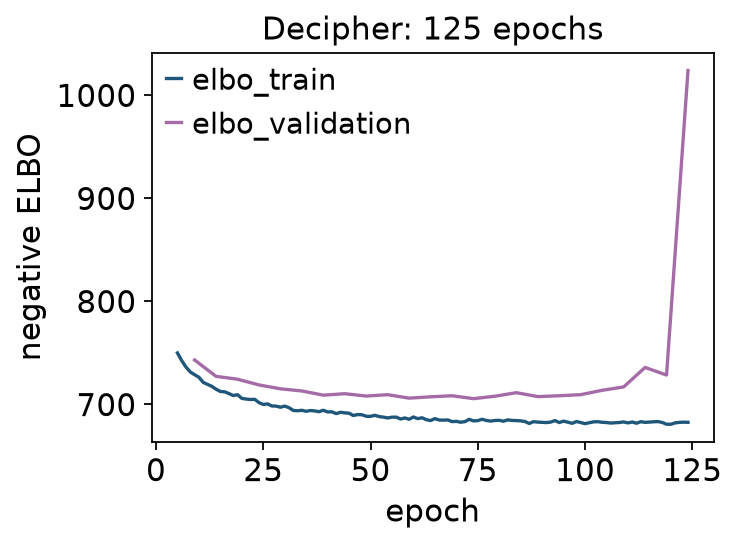

In [10]:
ov.vi.plot_history(model, skip_first=5);

In [11]:
v_mem = model.get_latent_representation()
z_mem = model.get_latent_representation(give_z=True)
pt = adata.obs['GEX_pseudotime_order'].to_numpy()
rho_axes = [spearmanr(v_mem[:, k], pt).statistic for k in range(2)]
print('decipher-space axes vs. reference (Palantir) pseudotime, Spearman rho:', np.round(rho_axes, 3))

decipher-space axes vs. reference (Palantir) pseudotime, Spearman rho: [-0.025  0.846]


This run's best axis gives `|rho| = 0.846` against the ground-truth
pseudotime -- a good optimum (clear of the ~0.75 threshold that separated
good/bad runs in the 16-seed sweep).


### Orient the Decipher space

`v` is identifiable only up to a rotation + reflection. `rotate_decipher_components`
does the same 100-angle x 2-reflection grid search as scvi-tools to align
component 1 with a chosen ordered label -- here the lineage order `LINEAGE` --
so axis 1 of every plot below reads left-to-right as HSC -> Reticulocyte.


In [12]:
adata.obsm['X_decipher'] = v_mem
adata.obsm['X_decipher_z'] = z_mem
v_rot, z_rot, rot = ov.vi.rotate_decipher_components(
    adata, 'X_decipher', 'X_decipher_z', v1_obs_col='cell_type', v1_order=LINEAGE)
adata.obsm['X_decipher'], adata.obsm['X_decipher_z'] = v_rot, z_rot

## The 2-D decipher space, by cell type and by donor

A single 2-D embedding with no separate UMAP step: cells should line up
along a continuum from HSC to Reticulocyte, with the three donors mixed
within each cell type (a biological axis, not a donor/batch axis).


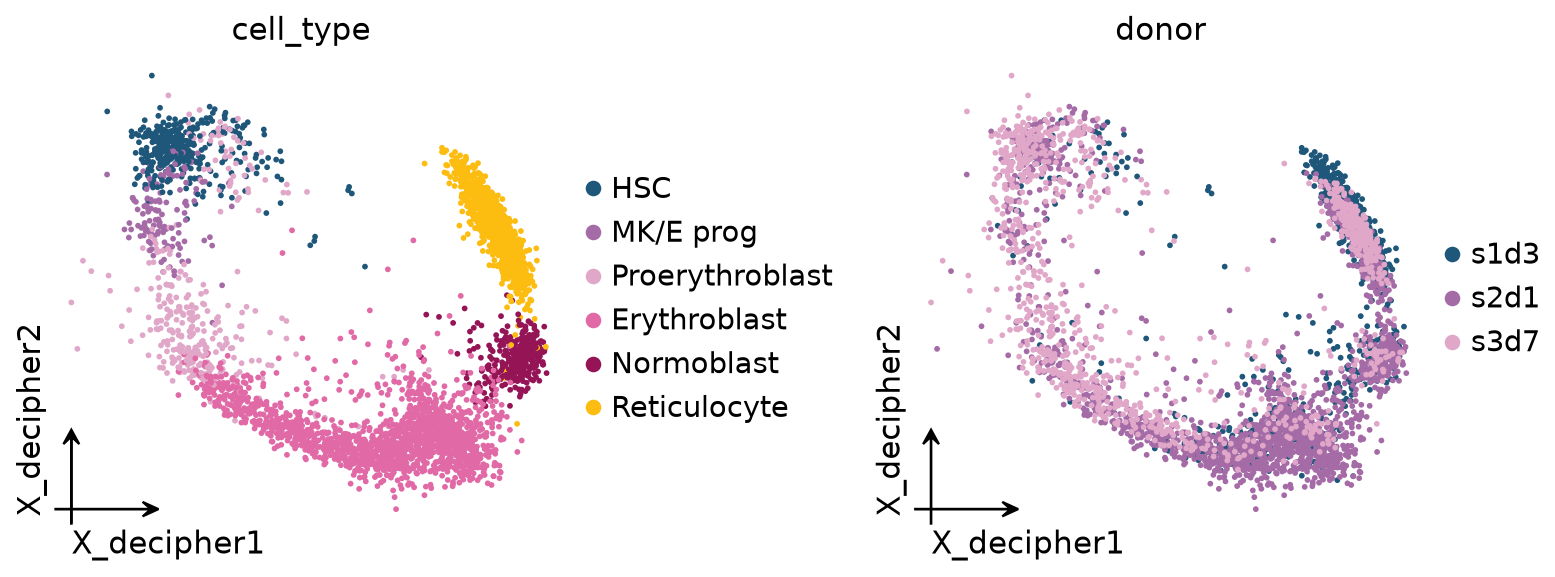

In [13]:
ov.pl.embedding(adata, basis='X_decipher', color=['cell_type', 'donor'], frameon='small', wspace=0.4)

As expected: a single continuous arc from HSC (top left) through MK/E
progenitors, Proerythroblast, Erythroblast and Normoblast to Reticulocyte
(top right, its own tight island -- reticulocytes are transcriptionally
near-silent and morphologically the most distinct stage). The three donors
overlap within every cell type in the right-hand panel: the axis Decipher
has found is the differentiation axis, not a donor effect.


## Trajectory: HSC -> erythroid

`ov.vi.Trajectory.from_clusters` builds a piecewise-linear path through the
per-cell-type centroids of the Decipher space, visited in the biological
order `LINEAGE`.


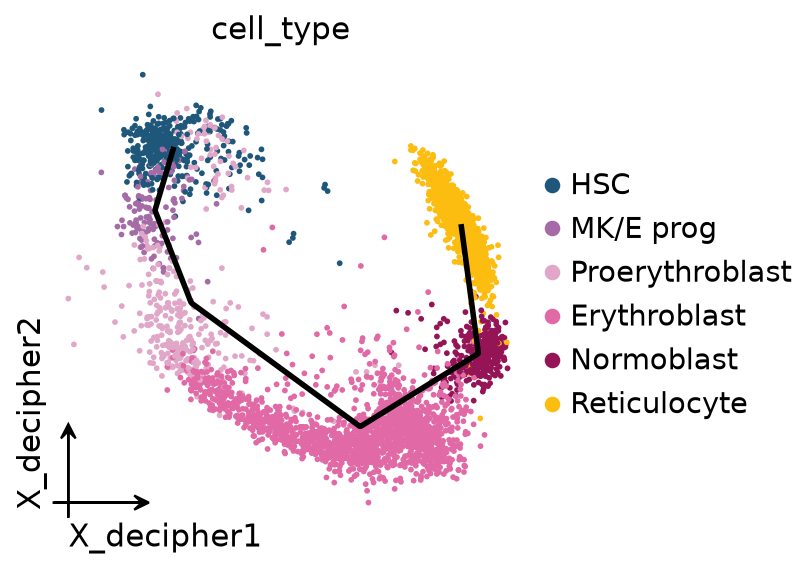

In [14]:
traj = ov.vi.Trajectory.from_clusters(adata, 'X_decipher', 'cell_type', LINEAGE)
fig, ax = plt.subplots(figsize=(4, 4))
ov.pl.embedding(adata, basis='X_decipher', color='cell_type', ax=ax, show=False, frameon='small')
ax.plot(traj.trajectory_latent[:, 0], traj.trajectory_latent[:, 1], color='black', lw=2.5)
plt.show()

The piecewise path hugs the dense part of the point cloud all the way
from the HSC cluster to the Reticulocyte island, confirming the centroid
order is a reasonable summary of this arc (no cluster is badly off to the
side of its neighbours).


## Decipher time vs. the reference pseudotime

`ov.vi.compute_decipher_time` is a KNN regression of the trajectory's time
coordinate onto every cell's position in the Decipher space -- a pseudotime
that needs no extra root-finding, since the trajectory already encodes the
direction.


In [15]:
adata.obs['decipher_time'] = ov.vi.compute_decipher_time(adata, 'cell_type', traj)
rho_dt = spearmanr(adata.obs['decipher_time'], adata.obs['GEX_pseudotime_order']).statistic
print(f'decipher time vs. reference (Palantir) pseudotime: Spearman rho = {rho_dt:.3f}')

decipher time vs. reference (Palantir) pseudotime: Spearman rho = 0.910


<Axes: xlabel='reference pseudotime (Palantir)', ylabel='decipher time'>

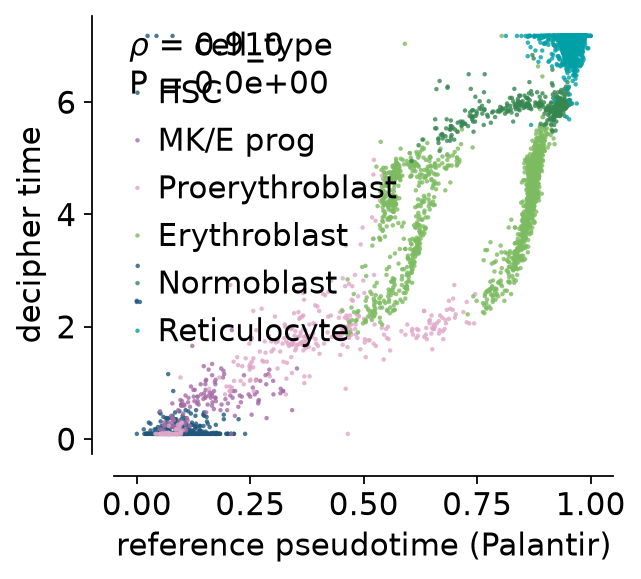

In [16]:
ov.pl.scatterplot(adata.obs, 'GEX_pseudotime_order', 'decipher_time', hue='cell_type',
                  hue_order=LINEAGE, corr='spearman', s=4,
                  xlabel='reference pseudotime (Palantir)', ylabel='decipher time')

`rho = 0.910` -- slightly higher than the raw `v` axis correlation above,
because the KNN regression along the trajectory smooths out some of the
per-cell noise in `v`. The relationship is monotonic across the full
lineage, and the colour-by-cell-type bands fall in the right order
(HSC/MK-E at low pseudotime, Reticulocyte at high) in both coordinates.


## Imputed gene patterns along the trajectory

`model.compute_gene_patterns` decodes the trajectory's points through
`v -> z -> x` and returns the mean plus a `[q25, q75]` band over `n_samples`
posterior draws of `z`, in units of expected counts at a fixed library size.
For this lineage the expected order is: `GATA1` (master erythroid TF, already
up in HSC/MK-E progenitors) -> `KLF1` (switches on with/after `GATA1`, drives
the terminal erythroid programme) -> `HBB` (haemoglobin, induced very late and
by far the largest fold-change).

> **Gotcha.** `decoder_v_to_z` only understands the model's native
> (un-rotated) `v`. `traj` above was built from the *rotated* `X_decipher`
> (for plotting), so decoding it directly would silently feed the decoder
> coordinates it never saw in training -- pass the same `rotation=rot` from
> `rotate_decipher_components` to undo it first (fixed in
> `vi/decipher-patterns`; omicverse PR pending).


In [17]:
pat = model.compute_gene_patterns(trajectory=traj, n_samples=100, rotation=rot)
genes_plot = ['GATA1', 'KLF1', 'HBB']

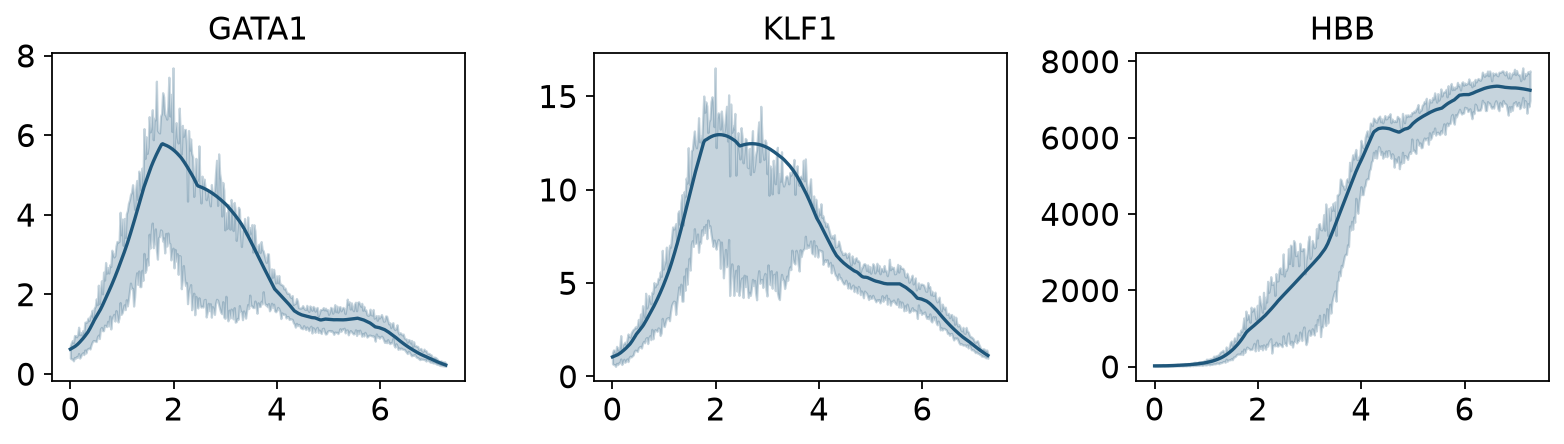

In [18]:
fig, axes = plt.subplots(1, len(genes_plot), figsize=(10, 3))
for ax, g in zip(axes, genes_plot):
    j = adata.var_names.get_loc(g)
    ax.plot(pat['times'], pat['mean'][:, j], color='C0')
    ax.fill_between(pat['times'], pat['q25'][:, j], pat['q75'][:, j], alpha=0.25, color='C0')
    ax.set_title(g)
plt.tight_layout()
plt.show()

The order holds, and -- with the rotation now handled correctly -- the
curves are the simple, biologically unsurprising shapes they should be:
`GATA1` and `KLF1` rise together early (the MK/E-progenitor ->
Proerythroblast transition, consistent with `KLF1` being a direct
transcriptional target of `GATA1`), peak around early-mid Erythroblast, then
decline through Normoblast into the Reticulocyte stage as transcription
winds down ahead of enucleation. `HBB` rises smoothly and close to
monotonically across the whole lineage, saturating in the Reticulocyte
stage -- consistent with checking the raw counts directly (mean HBB per
cell type: HSC 7, MK/E prog 15, Proerythroblast 799, Erythroblast 4794,
Normoblast 4910, Reticulocyte 7216): the classic order of transcription-factor
induction before the much larger, later induction of the effector gene
(haemoglobin) they activate.

Earlier executions of this notebook showed a spurious double-hump here
(including an `HBB` value crashing to ~0 and back) -- not biology. It was a
rotation bug: `traj` is built from the *rotated* `X_decipher` (for plotting),
but `decoder_v_to_z` only understands the model's native, un-rotated `v`, so
decoding the rotated trajectory directly fed the decoder coordinates it had
never seen in training. Fixed by passing `rotation=rot` to
`compute_gene_patterns` above (undoes the rotation before decoding) --
confirmed against the real per-cell-type counts, and against a freshly
trained reference `scvi.external.Decipher`, which shows the same kind of
decode-space sensitivity if you make the same mistake with its own
`compute_gene_patterns`. Not a trajectory-sampling or numerical-precision bug
in either stack.


## Training directly from disk (AnnDataOOM)

`ov.read(path, storage='disk')` returns an **AnnDataOOM**: `obs`/`var` stay
in memory, the count matrix stays in the `.h5ad` file and is streamed in
row blocks by anndataoom-fast's `pread` reader -- no scvi-tools needed here
either, and no HDF5 lock on the file. For a fixed block shuffle and a fixed
small number of epochs, training from disk reproduces the in-memory latent
(`benchmarks/vi/results_decipher.md`, "AnnDataOOM / Dask" section, shows this
bit-exactly on this same dataset).


In [19]:
h5ad_path = 'data/erythroid_lineage.h5ad'
adata.write_h5ad(h5ad_path)
KW = dict(max_epochs=15, batch_size=128, device='cpu', progress=False, seed=4,
          shuffle='block', block_size=256, buffer_blocks=4)
model_chk = ov.vi.Decipher(adata, layer='counts', seed=4, dim_v=2, dim_z=10, beta=0.1)
model_chk.train(**KW)

Decipher(n_obs=4454, n_vars=2005, dim_v=2, dim_z=10, beta=0.1, trained=True)

In [20]:
adata_disk = ov.read(h5ad_path, storage='disk')
model_disk = ov.vi.Decipher(adata_disk, layer='counts', seed=4, dim_v=2, dim_z=10, beta=0.1)
model_disk.train(**KW)
z_disk = model_disk.get_latent_representation()
print('max |delta|, in-memory vs. AnnDataOOM:', np.abs(model_chk.get_latent_representation() - z_disk).max())

📂 Reading with anndata-rs (Rust · out-of-memory)
   data/erythroid_lineage.h5ad  (19.1 MB)
   ✓ Loaded in 0.06s

💡 Data stays on disk. Use ov.pp.* for chunked processing.
   adata.close() when done · adata.to_adata() to materialise


max |delta|, in-memory vs. AnnDataOOM: 0.0


`max |delta| = 0.0`: bit-exact, matching the AnnDataOOM/Dask section of
`results_decipher.md` on this same dataset.


## Convenience wrapper

`ov.single.decipher(adata, layer='counts', key_added='X_decipher', **kwargs)`
does the train-and-store in one call for the common case (writes `v` to
`adata.obsm[key_added]`, and `z` too with `key_added_z=`); use `ov.vi.Decipher`
directly (as above) when you need the trajectory tools, `get_marginal_ll`,
`compute_imputed_gene_expression`, or `load_scvi_weights`.

## Related tutorials

- [t_vi](../../batch/t_vi.ipynb) -- the `ov.vi` API in memory, from disk and on the GPU, in more depth (SCVI/SCANVI).
- [t_traj_palantir](../t_traj_palantir.ipynb), [t_traj_slingshot](../../t_traj_slingshot.ipynb) -- pseudotime from a 1-D/branching ordering rather than a learned 2-D interpretable space.
- `benchmarks/vi/results_decipher.md` (omicverse repo) -- the full seed-sweep validation referenced above.
